# Retail Sales: Data Ingestion, Cleaning & Preprocessing with Pandas

**Programme:** Data Analytics & Business Intelligence Internship  |  **Task:** Data Ingestion, Cleaning & Preprocessing
**Prepared by:** Gurusaiprasadreddy

---

## Objective
Take a messy, real-world style transaction export (10,000+ rows) and turn it into a trustworthy, analysis-ready dataset. The raw file contains missing values, duplicate records, inconsistent data types, inconsistent labels and outliers, which is typical of what lands in an analyst's inbox.

## Workflow
| # | Stage | What happens |
|---|-------|--------------|
| 1 | Ingest | Load the raw CSV exactly as received |
| 2 | Profile | Quantify every data-quality problem *before* touching anything |
| 3 | Text hygiene | Trim whitespace, convert disguised placeholders (`?`, `-`, `unknown`) to real missing values |
| 4 | De-duplicate | Remove exact copies and near-duplicate records on the business key |
| 5 | Data types | Parse mixed date formats, strip currency symbols / `%` / words from numbers |
| 6 | Standardise labels | Collapse typos and casing variants into one canonical label per category |
| 7 | Validate & treat outliers | Business-rule checks plus statistical outlier detection |
| 8 | Impute missing values | Recover from master data and from the sales identity first, statistical fallbacks last |
| 9 | Feature engineering | Date parts, shipping lead time, discount %, profit margin, flags |
| 10 | Validate & export | Automated integrity checks, then write `clean_dataset.csv` |
| 11 | Before / after | Side-by-side quality scorecard, charts, full audit log, data dictionary |

## About the data
The raw file `raw_retail_sales.csv` is a **simulated retail transaction export** (generated by `generate_raw_data.py`) built to reproduce realistic defects found in real systems: mixed date formats, `$1,234.50` text in numeric columns, accounting-style negatives `($12.00)`, typos like `Eest`/`Technolgy`, and duplicated order lines. To run this notebook on a different raw export with the same columns, only change `RAW_PATH` in the next cell.

## Key assumptions (documented so they can be challenged)
* Slash-separated dates (`15/03/2024`) are **day/month/year**.
* Negative quantities are sign-entry errors, not returns, so they are converted to positive.
* `sales = quantity × unit_price × (1 − discount)`. This identity is used to *recover* a missing value from the other three before any statistical guess is made.
* A product's name, category and sub-category are defined by `product_id` (product master); a customer's name, segment, region and city by `customer_id`.
* Orders whose date cannot be recovered from any source are dropped, because month/year analysis is impossible without them.

In [1]:
import re
import difflib
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 160)
pd.set_option("display.float_format", lambda v: f"{v:,.2f}")

import os
from pathlib import Path

# ---------------- configuration ----------------
# Auto-detect data path whether executed from project root or inside notebooks/
def _resolve_data_path(filename):
    for candidate in [Path("..") / "data" / filename, Path("data") / filename, Path(filename)]:
        if candidate.exists():
            return str(candidate)
    return str(Path("..") / "data" / filename if Path("..").joinpath("data").exists() else Path("data") / filename)

RAW_PATH    = _resolve_data_path("raw_retail_sales.csv")
CLEAN_PATH  = str(Path("..") / "data" / "clean_dataset.csv") if Path("../data").exists() else (str(Path("data") / "clean_dataset.csv") if Path("data").exists() else "clean_dataset.csv")
AS_OF_DATE  = pd.Timestamp("2026-10-16")   # orders after this date are impossible
MIN_DATE    = pd.Timestamp("2015-01-01")   # orders before this date are implausible
MAX_LEAD    = 30                           # ship date more than 30 days after order = suspect

# ---------------- chart style (one hue per entity, recessive grid) ----------------
BLUE, ORANGE, GRAY = "#2a78d6", "#eb6834", "#9a9992"
INK, INK2, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e1", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": GRID,
    "axes.labelcolor": INK2, "xtick.color": INK2, "ytick.color": INK2, "text.color": INK,
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
    "grid.color": GRID, "grid.linewidth": 0.6, "axes.titleweight": "bold",
    "axes.titlesize": 11, "axes.titlelocation": "left", "font.size": 10, "figure.dpi": 110,
})

cleaning_log = []   # audit trail: one row per cleaning action


def log(step, issue, affected, action):
    cleaning_log.append({"Step": step, "Issue found": issue,
                         "Rows / cells affected": int(affected), "Action taken": action})

## 1. Ingest the raw data
The file is loaded as received, with no manual edits, and a pristine copy (`df_raw`) is kept so every "before" number in this notebook is traceable.

In [2]:
df_raw = pd.read_csv(RAW_PATH)
df = df_raw.copy()

print(f"Loaded {RAW_PATH}: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
df_raw.head(8)

Loaded raw_retail_sales.csv: 10,820 rows x 20 columns


,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,region,city,product_id,product_name,category,sub_category,quantity,unit_price,discount,sales,cost,profit,payment_method
0,ORD-110053,04-Nov-2024,01/11/2024,Standard Class,CUST-2190,Sofia Thomas,NaN,Central,Kansas City,PRD-022,Marker Set,Office Supplies,Art,2,84.78,0.2,135.65,$107.50,28.15,Debit Card
1,ORD-108577,30/05/2023,"Jun 03, 2023",2nd Class,CUST-2345,Barbara Chen,Consumer,East,Washington,PRD-018,Binder Dividers,NaN,Binders,8,$57.96,?,$463.68,278.67,185.01,Credit Card
2,ORD-106491,03/05/2025,2025-05-08,NaN,CUST-2261,Mary Patel,Consumer,Central,Kansas City,PRD-031,Laser Copier L5,Technology,Copiers,8,"$1,179.30",0.1,"$8,490.96",6387.09,"$2,103.87",Credit Card
3,ORD-102400,18/04/2023,24/04/2023,Standard Class,CUST-1337,JESSICA MOORE,corporate,Central,Minneapolis,PRD-013,Copy Paper Ream,Office Supplies,Paper,1,$93.45,NaN,93.45,56.35,37.1,DC
4,ORD-102346,2025-04-23,2025-04-28,Second Class,CUST-0910,William Sharma,Corporate,Central,Kansas City,PRD-030,Mechanical Keyboard,Technology,Accessories,3,"$2,736.50",0.2,656.76,476.97,179.79,credit card
5,ORD-101754,12/06/2025,2025-06-20,STANDARD CLASS,CUST-1497,Carlos Reddy,Corporate,West,Denver,PRD-020,Storage Box Set,Office Supplies,Storage,5,30.2,0.2,120.8,110.38,10.42,Credit Card
6,ORD-104617,16-Jun-2023,2023-06-21,Standard,CUST-0351,Omar Jones,Corporate,East,Washington,PRD-015,Sticky Notes Pack,Office Supplies,Paper,3,$22.43,0.1,60.56,49.39,11.17,Credit Card
7,ORD-103527,2023-11-15,NaN,Standard Class,CUST-1435,Mary Taylor,Home Office,South,Miami,PRD-033,Color Copier CX,Technology,Copiers,1,1175.43,0%,1175.43,821.63,353.8,Debit Card


## 2. Profile the raw data (BEFORE)
Before changing anything, quantify the damage. Two views matter: real `NaN`s, and **disguised** missing values (`?`, `-`, `unknown`) that pandas does not recognise on its own.

In [3]:
TOKENS    = {"", "n/a", "na", "null", "none", "nan", "?", "-", "unknown"}
CAT_COLS  = ["region", "category", "segment", "ship_mode", "payment_method"]
NUM_COLS  = ["quantity", "unit_price", "discount", "sales", "cost", "profit"]
DATE_COLS = ["order_date", "ship_date"]


def missing_cells(frame, unknown_is_missing=True):
    """Missing cells per column: real NaN plus disguised placeholders.
    In the cleaned data an explicit 'Unknown' label is a deliberate choice, not a defect, so it is not counted there."""
    tokens = TOKENS if unknown_is_missing else TOKENS - {"unknown"}
    out = {}
    for c in frame.columns:
        s = frame[c]
        placeholder = s.astype("string").str.strip().str.lower().isin(tokens)
        out[c] = int((s.isna() | placeholder).sum())
    return pd.Series(out)


def quality_report(frame, final=False):
    miss = missing_cells(frame, unknown_is_missing=not final)
    wrong = [c for c in NUM_COLS if not pd.api.types.is_numeric_dtype(frame[c])] + \
            [c for c in DATE_COLS if not pd.api.types.is_datetime64_any_dtype(frame[c])]
    return {
        "Rows": len(frame),
        "Columns": frame.shape[1],
        "Exact duplicate rows": int(frame.duplicated().sum()),
        "Repeated order IDs": int(frame["order_id"].duplicated().sum()),
        "Missing cells (incl. disguised)": int(miss.sum()),
        "Missing cells (% of all cells)": round(miss.sum() / frame.size * 100, 2),
        "Cells labelled 'Unknown' (unrecoverable, not guessed)": int((frame.astype("string") == "Unknown").sum().sum()),
        "Numeric/date columns stored as text": len(wrong),
        "Distinct labels in 5 category columns": int(sum(frame[c].nunique() for c in CAT_COLS)),
    }


before = quality_report(df_raw)
miss_before = missing_cells(df_raw)

profile = pd.DataFrame({
    "dtype": df_raw.dtypes.astype(str),
    "true NaN": df_raw.isna().sum(),
    "NaN + placeholders": miss_before,
    "% missing": (miss_before / len(df_raw) * 100).round(2),
}).sort_values("% missing", ascending=False)

print("RAW DATA QUALITY SCORECARD")
print(pd.Series(before).to_string())
profile

RAW DATA QUALITY SCORECARD
Rows                                                    10,820.00
Columns                                                     20.00
Exact duplicate rows                                       300.00
Repeated order IDs                                         420.00
Missing cells (incl. disguised)                          4,956.00
Missing cells (% of all cells)                               2.29
Cells labelled 'Unknown' (unrecoverable, not guessed)        0.00
Numeric/date columns stored as text                          8.00
Distinct labels in 5 category columns                      124.00


,dtype,true NaN,NaN + placeholders,% missing
cost,str,310,455,4.21
unit_price,str,268,383,3.54
region,str,257,368,3.40
discount,str,256,355,3.28
quantity,str,246,349,3.23
sales,str,241,341,3.15
customer_name,str,242,324,2.99
profit,str,231,320,2.96
ship_mode,str,214,310,2.87
category,str,202,286,2.64


In [4]:
# What does "messy" actually look like? A sample of distinct raw values per problem column.
for col in ["order_date", "quantity", "unit_price", "discount", "profit", "region", "category", "payment_method"]:
    vals = df_raw[col].dropna().astype(str).unique()
    print(f"{col:<15} {len(vals):>5} distinct  e.g. {list(vals[:9])}")

order_date       3772 distinct  e.g. ['04-Nov-2024', '30/05/2023', '03/05/2025', '18/04/2023', '2025-04-23', '12/06/2025', '16-Jun-2023', '2023-11-15', '2025-04-07']
quantity           42 distinct  e.g. ['2', '8', '1', '3', '5', '6', '-', '7', '4']
unit_price       8963 distinct  e.g. ['84.78', '$57.96', '$1,179.30', '$93.45', '$2,736.50', '30.2', '$22.43', '1175.43', '$756.83']
discount           25 distinct  e.g. ['0.2', '?', '0.1', '0%', '0.0', '0.15', '0.00', '10%', '0.05']
profit           9374 distinct  e.g. ['28.15', '185.01', '$2,103.87', '37.1', '179.79', '10.42', '11.17', '353.8', '270.94']
region             43 distinct  e.g. ['Central', 'East', 'West', 'South', 'West ', 'Central ', 'EAST', 'E', 'CENTRAL']
category           23 distinct  e.g. ['Office Supplies', 'Technology', 'furniture', 'Technolgy ', 'TECHNOLOGY', 'Furniture', 'OFFICE SUPPLIES', 'office supplies', 'FURNITURE']
payment_method     23 distinct  e.g. ['Debit Card', 'Credit Card', 'DC', 'credit card', 'upi', 'C

## 3. Text hygiene and disguised missing values
Trim and collapse whitespace on every column, then convert placeholders such as `?`, `-`, `unknown`, `N/A` into genuine missing values so that they can be handled properly later.

In [5]:
def clean_text(s):
    s = s.astype("string").str.strip().str.replace(r"\s+", " ", regex=True)
    return s.mask(s.str.lower().isin(TOKENS))


nan_before = int(df.isna().sum().sum())
df = df.apply(clean_text)
placeholders_fixed = int(df.isna().sum().sum()) - nan_before

log("3 Text hygiene", "Leading/trailing/double spaces and disguised placeholders ('?', '-', 'unknown', ...)",
    placeholders_fixed, "Trimmed text; converted placeholders to real missing values")
print(f"Disguised placeholders converted to real NaN: {placeholders_fixed:,}")

Disguised placeholders converted to real NaN: 1,449


## 4. Remove duplicate records
Two kinds of duplicates exist: **exact copies**, and **near-duplicates** that share an `order_id` but differ in casing/spacing. `order_id` is the business key, so for each order the most complete record is kept.

In [6]:
rows_start = len(df)

exact_dups = int(df.duplicated().sum())
df = df.drop_duplicates()

df["_filled"] = df.notna().sum(axis=1)
near_dups = int(df["order_id"].duplicated().sum())
df = (df.sort_values(["order_id", "_filled"], ascending=[True, False], kind="stable")
        .drop_duplicates(subset="order_id", keep="first")
        .drop(columns="_filled"))

log("4 Duplicates", "Exact duplicate rows", exact_dups, "Dropped, keeping first occurrence")
log("4 Duplicates", "Near-duplicates: same order_id, different casing/spacing", near_dups,
    "Kept the most complete record per order_id")
print(f"Exact duplicates removed:  {exact_dups:,}")
print(f"Near-duplicates removed:   {near_dups:,}")
print(f"Rows: {rows_start:,} -> {len(df):,}   |  order_id unique: {df['order_id'].is_unique}")

Exact duplicates removed:  300
Near-duplicates removed:   120
Rows: 10,820 -> 10,400   |  order_id unique: True


## 5. Fix data types
Dates arrive in four different formats and numeric columns carry `$`, `,`, `%`, `USD`, words (`three`), units (`2 units`) and accounting negatives `($12.00)`. Each is parsed with a dedicated, explicit function. Values that cannot be parsed become missing and are handled in the imputation step.

In [7]:
DATE_FORMATS = ["%Y-%m-%d", "%d/%m/%Y", "%b %d, %Y", "%d-%b-%Y"]
WORDS = {"zero": "0", "one": "1", "two": "2", "three": "3", "four": "4", "five": "5",
         "six": "6", "seven": "7", "eight": "8", "nine": "9", "ten": "10"}


def parse_dates(s):
    """Try each known format in turn; anything unparseable (e.g. 31/02/2024) becomes NaT."""
    out = pd.to_datetime(s, format=DATE_FORMATS[0], errors="coerce")
    for fmt in DATE_FORMATS[1:]:
        out = out.fillna(pd.to_datetime(s, format=fmt, errors="coerce"))
    return out


def to_number(s):
    """'$1,234.50' -> 1234.5 | '(12.00)' -> -12 | 'USD 9' -> 9 | '2 units' -> 2 | 'three' -> 3"""
    s = s.astype("string").str.strip().str.lower().replace(WORDS)
    neg = s.str.startswith("(").fillna(False).astype(bool) & s.str.endswith(")").fillna(False).astype(bool)
    num = pd.to_numeric(s.str.replace(r"[^0-9.\-]", "", regex=True), errors="coerce").astype("float64")
    return num.where(~neg, -num.abs())


def parse_discount(s):
    """'10%' -> 0.10 | '0.10' -> 0.10 | 10 -> 0.10"""
    s = s.astype("string").str.strip()
    has_pct = s.str.contains("%", regex=False).fillna(False).astype(bool)
    num = to_number(s)
    num = num.where(~has_pct, num / 100)
    return num.where(num <= 1, num / 100)


for c in DATE_COLS:
    parsed = parse_dates(df[c])
    unparseable = int((df[c].notna() & parsed.isna()).sum())
    df[c] = parsed
    log("5 Data types", f"{c}: stored as text in 4 formats; impossible dates (31/02/2024, month 13)",
        unparseable, "Parsed to datetime64 (4 formats); unparseable values set to NaT")
    print(f"{c}: parsed OK, {unparseable} impossible/unparseable dates set to NaT")

plain_number = r"-?\d+(\.\d+)?"
needed_conversion = 0
for c in NUM_COLS:
    needed_conversion += int((df[c].notna() & ~df[c].str.fullmatch(plain_number).fillna(False)).sum())
    df[c] = parse_discount(df[c]) if c == "discount" else to_number(df[c])

log("5 Data types", "Numeric cells containing $, commas, %, 'USD', units, words or accounting negatives",
    needed_conversion, "Converted quantity, unit_price, discount, sales, cost, profit to float64")
print(f"Numeric cells that were not plain numbers and needed conversion: {needed_conversion:,}")

print("Data types after parsing:")
df[DATE_COLS + NUM_COLS].dtypes.to_frame("dtype").T

order_date: parsed OK, 39 impossible/unparseable dates set to NaT
ship_date: parsed OK, 0 impossible/unparseable dates set to NaT


Numeric cells that were not plain numbers and needed conversion: 13,871
Data types after parsing:


,order_date,ship_date,quantity,unit_price,discount,sales,cost,profit
dtype,datetime64[us],datetime64[us],float64,float64,float64,float64,float64,float64


## 6. Standardise categorical labels
One canonical label per category. Each value is normalised (case, spacing, hyphens), looked up in an alias table (`E` -> `East`, `CC` -> `Credit Card`, `2nd Class` -> `Second Class`), and finally fuzzy-matched (`Technolgy` -> `Technology`, `Centrl` -> `Central`). A typo that is **equally close to two labels** (`Eest` could be East *or* West) is deliberately **not guessed**; it is left blank and recovered from the customer's other orders in Step 8.

In [8]:
CANONICAL = {
    "region":         ["East", "West", "South", "Central"],
    "category":       ["Furniture", "Office Supplies", "Technology"],
    "segment":        ["Consumer", "Corporate", "Home Office"],
    "ship_mode":      ["Standard Class", "Second Class", "First Class", "Same Day"],
    "payment_method": ["Credit Card", "Debit Card", "Cash", "UPI", "PayPal"],
}
ALIASES = {
    "region":         {"e": "East", "w": "West", "s": "South", "c": "Central"},
    "category":       {"tech": "Technology", "office supply": "Office Supplies"},
    "segment":        {"corp": "Corporate"},
    "ship_mode":      {"standard": "Standard Class", "second": "Second Class", "2nd class": "Second Class",
                       "first": "First Class", "1st class": "First Class"},
    "payment_method": {"cc": "Credit Card", "dc": "Debit Card"},
}


def standardize(series, canonical, aliases, cutoff=0.7):
    """Map every raw value to one canonical label.
    Order: exact match -> alias -> fuzzy match. A typo that is EQUALLY close to two different labels
    (e.g. 'Eest' = East or West) is never guessed: it is left blank and recovered from master data in Step 8."""
    lookup = {c.lower(): c for c in canonical}
    lookup.update(aliases)

    def fix(v):
        key = re.sub(r"[\s_\-]+", " ", str(v).strip().lower())
        if key in lookup:
            return lookup[key]
        scores = sorted(((difflib.SequenceMatcher(None, key, k).ratio(), k) for k in lookup), reverse=True)
        best_score, best_key = scores[0]
        if best_score < cutoff:
            return np.nan
        tied = {lookup[k] for s, k in scores if abs(s - best_score) < 1e-9}
        return lookup[best_key] if len(tied) == 1 else np.nan

    mapping = {u: fix(u) for u in series.dropna().unique()}      # map each distinct raw value once
    return series.map(mapping)


label_rows = []
for col in CAT_COLS:
    n_before = df[col].nunique()
    std = standardize(df[col], CANONICAL[col], ALIASES[col])
    changed = int((std.notna() & (df[col] != std)).sum())
    ambiguous = int((df[col].notna() & std.isna()).sum())
    df[col] = std
    assert df[col].dropna().isin(CANONICAL[col]).all(), f"unmapped labels left in {col}"
    label_rows.append({"column": col, "distinct labels before": n_before, "distinct labels after": df[col].nunique(),
                       "cells corrected": changed, "ambiguous (left blank)": ambiguous})
    log("6 Labels", f"{col}: casing / abbreviation / typo variants", changed,
        f"Mapped to {len(CANONICAL[col])} canonical labels")
    log("6 Labels", f"{col}: typo equally close to two labels (e.g. 'Eest' = East or West)", ambiguous,
        "Not guessed: left blank, recovered from master data in Step 8")

# free-text columns: consistent title case
df["customer_name"] = df["customer_name"].str.title()
df["city"] = df["city"].str.title()
df["sub_category"] = df["sub_category"].str.title()

pd.DataFrame(label_rows).set_index("column")

,distinct labels before,distinct labels after,cells corrected,ambiguous (left blank)
column,,,,
region,20,4,1617,115
category,15,3,1673,0
segment,12,3,1261,0
ship_mode,16,4,2065,0
payment_method,19,5,1915,0


## 7. Validate business rules and treat outliers
Statistical outliers are only meaningful relative to a sensible baseline, so each rule is tied to the business logic of the column. Flagged values are set to missing and **re-derived in Step 8** rather than deleted.

Quantity upper fence (Q3 + 3*IQR) = 14.0  ->  35 extreme values
Unit price more than 3x away from its product median -> 35 values


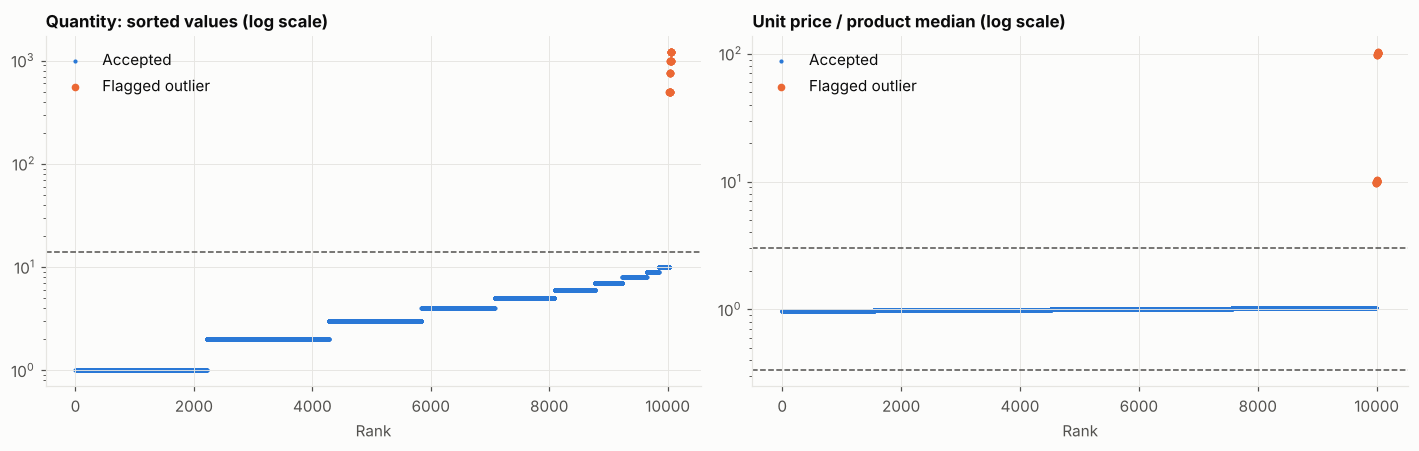

In [9]:
# ---- 7a. Quantity: sign errors and zeros --------------------------------------------------
neg_qty = df["quantity"] < 0
df.loc[neg_qty, "quantity"] = df.loc[neg_qty, "quantity"].abs()
zero_qty = df["quantity"] == 0
df.loc[zero_qty, "quantity"] = np.nan
log("7 Validation", "Negative quantities (sign-entry errors)", neg_qty.sum(), "Converted to absolute value")
log("7 Validation", "Zero quantities", zero_qty.sum(), "Set to missing (re-derived in Step 8)")

# ---- 7b. Quantity: extreme outliers, 3 x IQR fence -------------------------------------------
q1, q3 = df["quantity"].quantile([0.25, 0.75])
qty_upper = q3 + 3 * (q3 - q1)
qty_out = df["quantity"] > qty_upper

# ---- 7c. Unit price: compare each price with its own product's median -------------------------
price_ratio = df["unit_price"] / df.groupby("product_id")["unit_price"].transform("median")
price_out = (price_ratio > 3) | (price_ratio < 1 / 3)      # "extra zero" typos (x10, x100)

print(f"Quantity upper fence (Q3 + 3*IQR) = {qty_upper:.1f}  ->  {int(qty_out.sum())} extreme values")
print(f"Unit price more than 3x away from its product median -> {int(price_out.sum())} values")

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2))
for ax, vals, flag_mask, thr, title in [
    (axes[0], df["quantity"], qty_out, qty_upper, "Quantity: sorted values (log scale)"),
    (axes[1], price_ratio, price_out, None, "Unit price / product median (log scale)"),
]:
    v = vals.dropna()
    order = np.argsort(v.to_numpy())
    vs, fl = v.to_numpy()[order], flag_mask.loc[v.index].to_numpy()[order]
    x = np.arange(len(vs))
    ax.scatter(x[~fl], vs[~fl], s=3, color=BLUE, label="Accepted")
    ax.scatter(x[fl], vs[fl], s=16, color=ORANGE, label="Flagged outlier", zorder=3)
    ax.set_yscale("log"); ax.set_title(title); ax.set_xlabel("Rank"); ax.legend(frameon=False, loc="upper left")
axes[0].axhline(qty_upper, color=INK2, ls="--", lw=1)
axes[1].axhline(3, color=INK2, ls="--", lw=1); axes[1].axhline(1 / 3, color=INK2, ls="--", lw=1)
plt.tight_layout(); plt.show()

df.loc[qty_out, "quantity"] = np.nan
df.loc[price_out, "unit_price"] = np.nan
log("7 Outliers", "Extreme quantities (> Q3 + 3*IQR)", qty_out.sum(), "Set to missing (re-derived in Step 8)")
log("7 Outliers", "Unit price > 3x or < 1/3 of its product median ('extra zero' typos)", price_out.sum(),
    "Set to missing (re-derived in Step 8)")

In [10]:
# ---- 7d. Range checks on discount, sales and cost -----------------------------------------
bad_disc = df["discount"].notna() & ~df["discount"].between(0, 0.9)
df.loc[bad_disc, "discount"] = np.nan
bad_money = {c: (df[c] < 0) for c in ["unit_price", "sales", "cost"]}
for c, m in bad_money.items():
    df.loc[m, c] = np.nan
log("7 Validation", "Discount outside 0-90%", bad_disc.sum(), "Set to missing")
log("7 Validation", "Negative unit_price / sales / cost", sum(m.sum() for m in bad_money.values()), "Set to missing")

# ---- 7e. Dates: impossible years and shipping before ordering -----------------------------
out_of_window = df["order_date"].notna() & ((df["order_date"] > AS_OF_DATE) | (df["order_date"] < MIN_DATE))
df.loc[out_of_window, "order_date"] = pd.NaT

lead = (df["ship_date"] - df["order_date"]).dt.days
bad_ship = df["ship_date"].notna() & df["order_date"].notna() & ((lead < 0) | (lead > MAX_LEAD))
df.loc[bad_ship, "ship_date"] = pd.NaT
log("7 Validation", f"order_date in the future or before {MIN_DATE.year} (e.g. 2099)", out_of_window.sum(), "Set to NaT")
log("7 Validation", f"ship_date before order_date or > {MAX_LEAD} days after", bad_ship.sum(),
    "Set to NaT (re-derived from typical lead time)")

print(f"Discounts out of range: {int(bad_disc.sum())}  |  Impossible order dates: {int(out_of_window.sum())}  |  "
      f"Ship date before order date: {int(bad_ship.sum())}")

Discounts out of range: 0  |  Impossible order dates: 15  |  Ship date before order date: 162


## 8. Handle missing values
A rule of thumb used here: **derive before you estimate.** Missing values are recovered, in this order of trust, from
1. **Master data**: product attributes from `product_id`, customer attributes from `customer_id`.
2. **Exact business identities**: `sales = quantity × unit_price × (1 − discount)` and `ship_date = order_date + lead time`.
3. **Robust group statistics** (product median / mode) only when 1 and 2 are not possible.
4. A visible `Unknown` label for categorical fields with no recoverable value, so nothing is silently invented.

A row-level counter (`fields_repaired`) records how many fields were recovered, so analysts can filter repaired rows if needed.

In [11]:
df["_rep"] = 0   # counts how many fields of each row were recovered/imputed


def fill(col, values, step, note):
    """Fill missing cells of `col` from an aligned Series of candidate values."""
    m = df[col].isna() & values.notna()
    df.loc[m, col] = values[m]
    df.loc[m, "_rep"] += 1
    log(step, f"{col}: missing", m.sum(), note)
    return int(m.sum())


def mode_map(key, col):
    return df.dropna(subset=[col]).groupby(key)[col].agg(lambda s: s.mode().iloc[0])


# ---- 8a. Product master: product_id fully determines name / category / sub-category ------------
for col in ["product_name", "category", "sub_category"]:
    master = df["product_id"].map(mode_map("product_id", col))
    n_wrong = int((df[col].notna() & (df[col] != master)).sum())
    fill(col, master, "8a Product master", "Recovered from product_id")
    df.loc[df[col] != master, col] = master            # enforce one spelling per product
    if n_wrong:
        log("8a Product master", f"{col}: inconsistent with product_id", n_wrong, "Overwritten with master value")

# ---- 8b. Customer master: fill gaps from the customer's other orders ---------------------------
for col in ["customer_name", "segment", "region", "city"]:
    fill(col, df["customer_id"].map(mode_map("customer_id", col)), "8b Customer master", "Recovered from customer_id")
fill("region", df["city"].map(mode_map("city", "region")), "8b Customer master", "Recovered from city (each city sits in one region)")

# ---- 8c. Remaining categorical gaps get an explicit label ------------------------------------
for col in ["customer_name", "segment", "region", "city", "ship_mode", "payment_method"]:
    n = int(df[col].isna().sum())
    df[col] = df[col].fillna("Unknown")
    log("8c Unknown label", f"{col}: no recoverable value", n, "Labelled 'Unknown' (not guessed)")

In [12]:
# ---- 8d. Dates: use the typical lead time of each ship mode --------------------------------
lead_days = (df["ship_date"] - df["order_date"]).dt.days
overall_lead = float(lead_days.median())
lead_by_mode = lead_days.groupby(df["ship_mode"]).median()
lead_by_mode["Unknown"] = overall_lead
mode_lead = pd.to_timedelta(df["ship_mode"].map(lead_by_mode).fillna(overall_lead).round(), unit="D")
print("Median shipping lead time (days) by ship mode:\n", lead_by_mode.round(1).to_string(), "\n")

obs_min, obs_max = df["order_date"].min(), df["order_date"].max()   # range of order dates actually recorded
m = df["order_date"].isna() & df["ship_date"].notna()
estimate = df.loc[m, "ship_date"] - mode_lead[m]
df.loc[m, "order_date"] = estimate.clip(lower=obs_min, upper=obs_max)    # an estimate may not leave the observed window
df.loc[m, "_rep"] += 1
log("8d Dates", "order_date missing/invalid but ship_date known", m.sum(),
    "order_date = ship_date - median lead time of ship mode (kept inside the observed date range)")
print(f"order_date estimated from ship_date for {int(m.sum())} rows "
      f"({int((estimate != estimate.clip(lower=obs_min, upper=obs_max)).sum())} pulled back into the observed window "
      f"{obs_min:%Y-%m-%d} to {obs_max:%Y-%m-%d})")

m = df["ship_date"].isna() & df["order_date"].notna()
df.loc[m, "ship_date"] = df.loc[m, "order_date"] + mode_lead[m]
df.loc[m, "_rep"] += 1
log("8d Dates", "ship_date missing/invalid", m.sum(), "ship_date = order_date + median lead time of ship mode")

unresolved = df["order_date"].isna()
log("8d Dates", "order_date AND ship_date both unusable", unresolved.sum(), "Rows dropped (no way to place the order in time)")
rows_before_drop = len(df)
df = df.loc[~unresolved].copy()
print(f"Rows dropped because the order date is unrecoverable: {int(unresolved.sum())}  ({rows_before_drop:,} -> {len(df):,})")

Median shipping lead time (days) by ship mode:
 ship_mode
First Class      2.00
Same Day         0.00
Second Class     4.00
Standard Class   7.00
Unknown          5.00 

order_date estimated from ship_date for 170 rows (1 pulled back into the observed window 2023-01-01 to 2025-12-31)
Rows dropped because the order date is unrecoverable: 4  (10,400 -> 10,396)


In [13]:
# ---- 8e. Numeric columns: exact algebra first -----------------------------------------------
# identity:  sales = quantity * unit_price * (1 - discount)  -> any ONE missing term can be solved
def solve_sales_identity(rounds=2):
    counts = {"sales": 0, "unit_price": 0, "quantity": 0, "discount": 0}
    for _ in range(rounds):
        q, p, d, s = df["quantity"], df["unit_price"], df["discount"], df["sales"]
        m = s.isna() & q.notna() & p.notna() & d.notna()
        df.loc[m, "sales"] = (q * p * (1 - d))[m].round(2); counts["sales"] += int(m.sum()); df.loc[m, "_rep"] += 1

        q, p, d, s = df["quantity"], df["unit_price"], df["discount"], df["sales"]
        m = p.isna() & q.notna() & d.notna() & s.notna()
        df.loc[m, "unit_price"] = (s / (q * (1 - d)))[m].round(2); counts["unit_price"] += int(m.sum()); df.loc[m, "_rep"] += 1

        q, p, d, s = df["quantity"], df["unit_price"], df["discount"], df["sales"]
        est = s / (p * (1 - d))
        m = q.isna() & p.notna() & d.notna() & s.notna() & ((est - est.round()).abs() < 0.05) & (est.round() >= 1)
        df.loc[m, "quantity"] = est[m].round(); counts["quantity"] += int(m.sum()); df.loc[m, "_rep"] += 1

        q, p, d, s = df["quantity"], df["unit_price"], df["discount"], df["sales"]
        est = 1 - s / (q * p)
        snap = (est / 0.05).round() * 0.05                      # discounts come in 5% steps
        m = d.isna() & q.notna() & p.notna() & s.notna() & ((est - snap).abs() <= 0.01) & snap.between(0, 0.5)
        df.loc[m, "discount"] = snap[m].round(2); counts["discount"] += int(m.sum()); df.loc[m, "_rep"] += 1
    return counts


for col, n in solve_sales_identity().items():
    log("8e Sales identity", f"{col}: missing/outlier, solved from the other three terms", n,
        "Exact derivation from sales = qty x price x (1 - discount)")
    print(f"{col:<11} derived exactly from the sales identity: {n:,}")

# ---- 8f. Two unknowns at once: search for the combination that reproduces the recorded sales --------
# (a) quantity AND discount missing, price + sales known -> try every plausible (quantity, discount) pair;
#     keep pairs that reproduce sales within 1% and break ties with how common each value is in the data.
q_freq = df.loc[df["quantity"] <= qty_upper, "quantity"].dropna().astype(int).value_counts(normalize=True)
d_freq = df["discount"].dropna().round(2).value_counts(normalize=True)
qs, ds = q_freq.index.to_numpy(float), d_freq.index.to_numpy(float)

rows = df.index[df["quantity"].isna() & df["discount"].isna() & df["unit_price"].notna() & df["sales"].notna()]
if len(rows):
    price, sales = df.loc[rows, "unit_price"].to_numpy()[:, None, None], df.loc[rows, "sales"].to_numpy()[:, None, None]
    rel = np.abs(price * qs[None, :, None] * (1 - ds[None, None, :]) - sales) / sales
    prior = q_freq.to_numpy()[:, None] * d_freq.to_numpy()[None, :]
    score = np.where(rel <= 0.01, prior[None, :, :], 0).reshape(len(rows), -1)
    ok = score.max(axis=1) > 0
    qi, di = np.unravel_index(score.argmax(axis=1), (len(qs), len(ds)))
    hit = rows[ok]
    df.loc[hit, "quantity"] = qs[qi[ok]]
    df.loc[hit, "discount"] = ds[di[ok]]
    df.loc[hit, "_rep"] += 2
    log("8f Joint solve", "quantity AND discount both missing (price + sales known)", len(hit),
        "Best-fitting (quantity, discount) pair that reproduces sales within 1%")
    print(f"quantity + discount recovered jointly: {len(hit)} of {len(rows)} rows")

# (b) price AND discount missing, quantity + sales known -> pick the discount whose implied price is
#     closest to the product's median price (must be within 5%).
prod_median = df.groupby("product_id")["unit_price"].transform("median")
rows = df.index[df["unit_price"].isna() & df["discount"].isna() & df["quantity"].notna() & df["sales"].notna()]
if len(rows):
    q_, s_, med = (df.loc[rows, "quantity"].to_numpy()[:, None], df.loc[rows, "sales"].to_numpy()[:, None],
                   prod_median.loc[rows].to_numpy()[:, None])
    implied = s_ / (q_ * (1 - ds[None, :]))
    dev = np.abs(implied / med - 1)
    ok = dev.min(axis=1) <= 0.05
    best = dev.argmin(axis=1)
    hit = rows[ok]
    df.loc[hit, "discount"] = ds[best[ok]]
    df.loc[hit, "unit_price"] = implied[np.arange(len(rows)), best][ok].round(2)
    df.loc[hit, "_rep"] += 2
    log("8f Joint solve", "unit_price AND discount both missing (quantity + sales known)", len(hit),
        "Discount whose implied price is closest to the product median price")
    print(f"unit_price + discount recovered jointly: {len(hit)} of {len(rows)} rows")

# ---- 8g. Statistical fallbacks for whatever is still missing ------------------------------------
fill("unit_price", df.groupby("product_id")["unit_price"].transform("median"), "8g Fallback", "Product median price")

# Even an *estimated* price is close enough (within a few %) to recover a whole-number quantity from sales
est_qty = df["sales"] / (df["unit_price"] * (1 - df["discount"]))
m = df["quantity"].isna() & (est_qty.round() >= 1) & ((est_qty - est_qty.round()).abs() / est_qty.round() <= 0.05)
df.loc[m, "quantity"] = est_qty[m].round(); df.loc[m, "_rep"] += 1
log("8g Fallback", "quantity: missing, recovered from sales / estimated price (rounded to whole units, within 5%)", m.sum(),
    "Derived from sales identity with product median price")

disc_mode = df["discount"].mode().iloc[0]
fill("discount", pd.Series(disc_mode, index=df.index), "8g Fallback", f"Most frequent discount ({disc_mode:.0%})")
fill("quantity", df.groupby("product_id")["quantity"].transform("median").round(), "8g Fallback", "Product median quantity")
fill("quantity", pd.Series(df["quantity"].median(), index=df.index), "8g Fallback", "Overall median quantity")
fill("sales", (df["quantity"] * df["unit_price"] * (1 - df["discount"])).round(2), "8g Fallback", "qty x price x (1 - discount)")

sales       derived exactly from the sales identity: 297
unit_price  derived exactly from the sales identity: 379
quantity    derived exactly from the sales identity: 335
discount    derived exactly from the sales identity: 315
quantity + discount recovered jointly: 13 of 13 rows
unit_price + discount recovered jointly: 6 of 6 rows


21

In [14]:
# ---- 8h. Cost: per-product cost ratio (cost / gross sales) from complete rows ----------------
cost_ratio = (df["cost"] / (df["quantity"] * df["unit_price"])).groupby(df["product_id"]).median()
fill("cost", (df["quantity"] * df["unit_price"] * df["product_id"].map(cost_ratio)).round(2),
     "8h Cost", "quantity x unit_price x product's median cost ratio")

# ---- 8i. Integrity check on the sales identity (before profit is derived from sales) --------------
identity = df["quantity"] * df["unit_price"] * (1 - df["discount"])
rel_err = (df["sales"] - identity).abs() / df["sales"].clip(lower=0.01)
broken = rel_err > 0.05
print(f"Rows where sales deviates >5% from qty x price x (1-discount): {int(broken.sum())}")
if broken.any():   # safety net: components imputed together can contradict the recorded sales
    df.loc[broken, "sales"] = identity[broken].round(2)
    df.loc[broken, "_rep"] += 1
    log("8i Integrity", "sales inconsistent with its (partly imputed) components", broken.sum(),
        "Sales recomputed from quantity x price x (1 - discount)")

# ---- 8j. Profit: single source of truth = sales - cost ---------------------------------------
profit_calc = (df["sales"] - df["cost"]).round(2)
profit_missing = int(df["profit"].isna().sum())
profit_wrong = int((df["profit"].notna() & ((df["profit"] - profit_calc).abs() > 0.05)).sum())
df.loc[df["profit"].isna(), "_rep"] += 1
df["profit"] = profit_calc
log("8j Profit", "profit: missing", profit_missing, "Recomputed as sales - cost")
log("8j Profit", "profit: disagrees with sales - cost by more than 5 cents", profit_wrong, "Overwritten with sales - cost")

print("\nMissing values remaining after imputation (should all be 0):")
df.isna().sum().to_frame("missing").T

Rows where sales deviates >5% from qty x price x (1-discount): 0

Missing values remaining after imputation (should all be 0):


,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,segment,region,city,product_id,product_name,category,sub_category,quantity,unit_price,discount,sales,cost,profit,payment_method,_rep
missing,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0


## 9. Feature engineering
New analysis-ready columns derived from the cleaned data: calendar attributes (for trend / seasonality analysis), shipping performance, discount and **profit margin** metrics, and simple flags.

In [15]:
df["quantity"] = df["quantity"].round().astype(int)

# --- calendar features -------------------------------------------------------------------
df["order_year"]       = df["order_date"].dt.year
df["order_month"]      = df["order_date"].dt.month
df["order_month_name"] = df["order_date"].dt.month_name().str[:3]
df["order_quarter"]    = "Q" + df["order_date"].dt.quarter.astype(str)
df["order_year_month"] = df["order_date"].dt.strftime("%Y-%m")
df["order_weekday"]    = df["order_date"].dt.day_name()
df["is_weekend"]       = df["order_date"].dt.dayofweek >= 5

# --- operational ---------------------------------------------------------------------------
df["shipping_days"] = (df["ship_date"] - df["order_date"]).dt.days

# --- financial -----------------------------------------------------------------------------
df["gross_sales"]       = (df["quantity"] * df["unit_price"]).round(2)
df["discount_pct"]      = (df["discount"] * 100).round(1)
df["discount_amount"]   = (df["gross_sales"] - df["sales"]).round(2)
df["profit_margin_pct"] = np.where(df["sales"] > 0, df["profit"] / df["sales"] * 100, 0).round(2)
df["is_loss_making"]    = df["profit"] < 0
df["order_size"]        = pd.cut(df["quantity"], bins=[0, 2, 5, np.inf],
                                 labels=["Small (1-2)", "Medium (3-5)", "Large (6+)"]).astype(str)

# --- data-quality lineage ---------------------------------------------------------------------
df["fields_repaired"] = df.pop("_rep").astype(int)
df["was_repaired"]    = df["fields_repaired"] > 0

new_features = ["order_year", "order_month", "order_month_name", "order_quarter", "order_year_month", "order_weekday",
                "is_weekend", "shipping_days", "gross_sales", "discount_pct", "discount_amount", "profit_margin_pct",
                "is_loss_making", "order_size", "fields_repaired", "was_repaired"]
log("9 Feature engineering", "Derived analysis columns", len(new_features),
    "Added: " + ", ".join(new_features))
df[["order_id", "order_date", "order_year", "order_month", "order_quarter", "shipping_days",
    "sales", "profit", "profit_margin_pct", "discount_pct", "is_loss_making", "order_size"]].head(8)

,order_id,order_date,order_year,order_month,order_quarter,shipping_days,sales,profit,profit_margin_pct,discount_pct,is_loss_making,order_size
1421,ORD-100000,2025-01-18,2025,1,Q1,8,681.95,75.77,11.11,10.00,False,Small (1-2)
8522,ORD-100001,2025-05-04,2025,5,Q2,5,240.42,21.21,8.82,15.00,False,Medium (3-5)
6781,ORD-100002,2025-10-05,2025,10,Q4,5,"1,179.89",339.06,28.74,5.00,False,Small (1-2)
4256,ORD-100003,2025-10-01,2025,10,Q4,7,"1,237.33",259.11,20.94,15.00,False,Large (6+)
3110,ORD-100004,2025-04-16,2025,4,Q2,7,21.44,4.87,22.71,5.00,False,Small (1-2)
1607,ORD-100005,2025-12-04,2025,12,Q4,6,"10,296.10","3,788.96",36.80,0.00,False,Large (6+)
6307,ORD-100006,2023-09-09,2023,9,Q3,4,178.78,33.79,18.90,0.00,False,Small (1-2)
8927,ORD-100007,2025-11-30,2025,11,Q4,5,"1,957.80",391.56,20.00,0.00,False,Medium (3-5)


## 10. Final validation and export
Every rule below is an automated assertion: if any fails, the notebook stops, so a dirty file can never be exported by accident.

In [16]:
FINAL_COLUMNS = [
    "order_id", "order_date", "ship_date", "shipping_days", "ship_mode",
    "customer_id", "customer_name", "segment", "region", "city",
    "product_id", "product_name", "category", "sub_category",
    "quantity", "unit_price", "discount", "discount_pct", "gross_sales", "discount_amount", "sales", "cost", "profit",
    "profit_margin_pct", "is_loss_making", "order_size", "payment_method",
    "order_year", "order_month", "order_month_name", "order_quarter", "order_year_month", "order_weekday", "is_weekend",
    "fields_repaired", "was_repaired",
]
clean = df[FINAL_COLUMNS].sort_values(["order_date", "order_id"]).reset_index(drop=True)

checks = {
    "no missing values anywhere":                    clean.isna().sum().sum() == 0,
    "order_id is unique (no duplicates)":            clean["order_id"].is_unique,
    "no exact duplicate rows":                       not clean.duplicated().any(),
    "dates are datetime64":                          all(pd.api.types.is_datetime64_any_dtype(clean[c]) for c in DATE_COLS),
    "numeric columns are numeric":                   all(pd.api.types.is_numeric_dtype(clean[c]) for c in NUM_COLS),
    "quantity is a positive integer":                bool((clean["quantity"] >= 1).all()),
    "discount within 0-90%":                         bool(clean["discount"].between(0, 0.9).all()),
    "unit_price, sales, cost are positive":          bool((clean[["unit_price", "sales", "cost"]] > 0).all().all()),
    "ship_date on/after order_date":                 bool((clean["ship_date"] >= clean["order_date"]).all()),
    "order dates inside valid window":               bool(clean["order_date"].between(MIN_DATE, AS_OF_DATE).all()),
    "profit == sales - cost":                        bool(((clean["profit"] - (clean["sales"] - clean["cost"])).abs() < 0.011).all()),
    "sales == qty x price x (1-disc) within 5%":     bool((((clean["sales"] - clean["quantity"] * clean["unit_price"] * (1 - clean["discount"])).abs()
                                                          / clean["sales"]) <= 0.05).all()),
    "only canonical labels in category columns":     all(clean[c].isin(CANONICAL[c] + ["Unknown"]).all() for c in CAT_COLS),
    "one name/category per product_id":              bool((clean.groupby("product_id")[["product_name", "category", "sub_category"]].nunique() == 1).all().all()),
}
report = pd.Series(checks).map({True: "PASS", False: "FAIL"})
print(report.to_string())
assert all(checks.values()), "Validation failed - do not export"
print("\nAll integrity checks passed")

clean.to_csv(CLEAN_PATH, index=False, date_format="%Y-%m-%d")
check = pd.read_csv(CLEAN_PATH, parse_dates=DATE_COLS)
print(f"\nExported {CLEAN_PATH}: {check.shape[0]:,} rows x {check.shape[1]} columns (re-read successfully)")

no missing values anywhere                   PASS
order_id is unique (no duplicates)           PASS
no exact duplicate rows                      PASS
dates are datetime64                         PASS
numeric columns are numeric                  PASS
quantity is a positive integer               PASS
discount within 0-90%                        PASS
unit_price, sales, cost are positive         PASS
ship_date on/after order_date                PASS
order dates inside valid window              PASS
profit == sales - cost                       PASS
sales == qty x price x (1-disc) within 5%    PASS
only canonical labels in category columns    PASS
one name/category per product_id             PASS

All integrity checks passed



Exported clean_dataset.csv: 10,396 rows x 36 columns (re-read successfully)


## 11. Before vs after
### 11.1 Data-quality scorecard

In [17]:
after = quality_report(clean, final=True)


def fmt(k, v):
    return f"{v:,.2f}%" if "%" in k else f"{int(v):,}"


scorecard = pd.DataFrame({"BEFORE (raw)": {k: fmt(k, v) for k, v in before.items()},
                          "AFTER (clean)": {k: fmt(k, v) for k, v in after.items()}})
scorecard["Change"] = ""
n_canon = sum(len(v) for v in CANONICAL.values())
n_unknown_cols = sum(bool((clean[c] == "Unknown").any()) for c in CAT_COLS)
scorecard.loc["Rows", "Change"] = f"{before['Rows'] - after['Rows']:,} duplicate / unusable rows removed"
scorecard.loc["Columns", "Change"] = f"+{after['Columns'] - before['Columns']} engineered features"
for k in ["Exact duplicate rows", "Repeated order IDs", "Missing cells (incl. disguised)",
          "Missing cells (% of all cells)", "Numeric/date columns stored as text"]:
    scorecard.loc[k, "Change"] = "resolved"
scorecard.loc["Cells labelled 'Unknown' (unrecoverable, not guessed)", "Change"] = "explicit label instead of a guess"
scorecard.loc["Distinct labels in 5 category columns", "Change"] = \
    f"{n_canon} canonical + 'Unknown' in {n_unknown_cols} columns"
scorecard

,BEFORE (raw),AFTER (clean),Change
Rows,"10,820","10,396",424 duplicate / unusable rows removed
Columns,20,36,+16 engineered features
Exact duplicate rows,300,0,resolved
Repeated order IDs,420,0,resolved
Missing cells (incl. disguised),"4,956",0,resolved
Missing cells (% of all cells),2.29%,0.00%,resolved
"Cells labelled 'Unknown' (unrecoverable, not guessed)",0,504,explicit label instead of a guess
Numeric/date columns stored as text,8,0,resolved
Distinct labels in 5 category columns,124,22,19 canonical + 'Unknown' in 3 columns


### 11.2 Visual proof

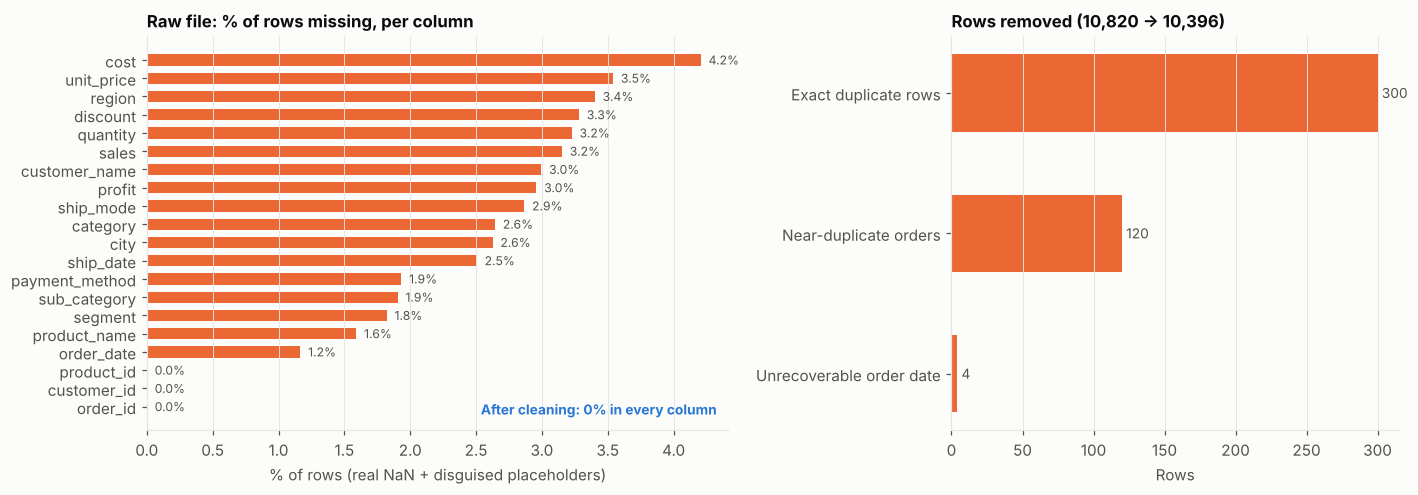

In [18]:
n_exact, n_near = exact_dups, near_dups
n_dates_dropped = int(unresolved.sum())

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), gridspec_kw={"width_ratios": [1.3, 1]})

ax = axes[0]
pct = (miss_before / len(df_raw) * 100).sort_values()
ax.barh(pct.index, pct.values, color=ORANGE, height=0.62)
for y, v in enumerate(pct.values):
    ax.text(v + 0.06, y, f"{v:.1f}%", va="center", fontsize=8, color=INK2)
ax.set_title("Raw file: % of rows missing, per column")
ax.set_xlabel("% of rows (real NaN + disguised placeholders)")
ax.grid(axis="y", visible=False)
ax.text(0.98, 0.04, "After cleaning: 0% in every column", transform=ax.transAxes, ha="right", fontsize=9,
        color=BLUE, fontweight="bold")

ax = axes[1]
labels = ["Exact duplicate rows", "Near-duplicate orders", "Unrecoverable order date"]
vals = [n_exact, n_near, n_dates_dropped]
ax.barh(labels[::-1], vals[::-1], color=ORANGE, height=0.55)
for y, v in enumerate(vals[::-1]):
    ax.text(v + max(vals) * 0.01, y, f"{v:,}", va="center", fontsize=9, color=INK2)
ax.set_title(f"Rows removed ({len(df_raw):,} -> {len(clean):,})")
ax.set_xlabel("Rows"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

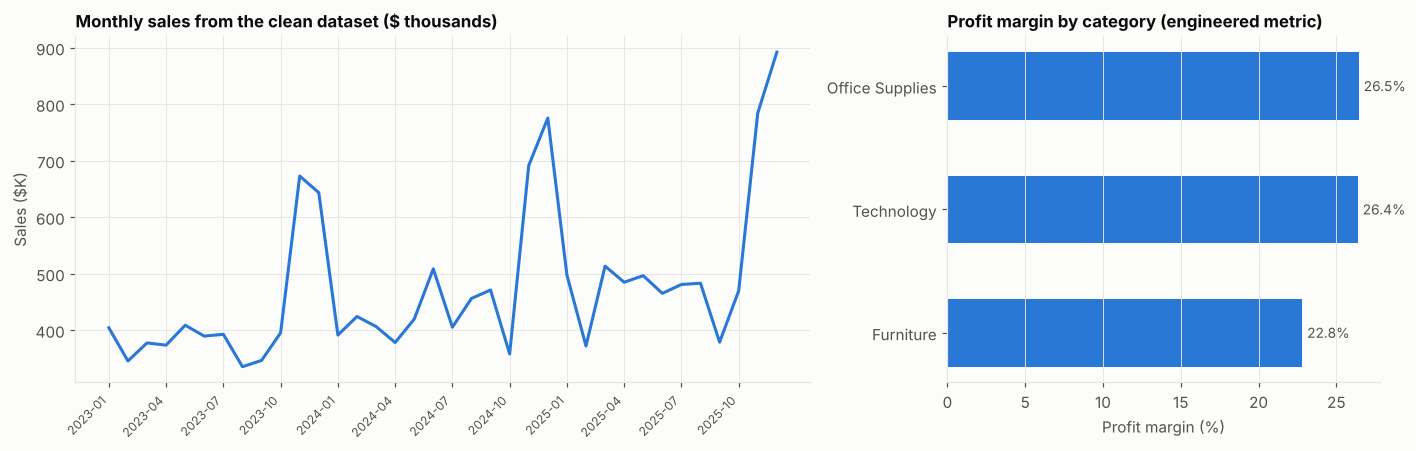

In [19]:
# Sanity check of the engineered features: do the cleaned numbers tell a coherent business story?
monthly = clean.groupby("order_year_month")["sales"].sum() / 1000
margin = clean.groupby("category").apply(lambda g: g["profit"].sum() / g["sales"].sum() * 100).sort_values()

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), gridspec_kw={"width_ratios": [1.7, 1]})
ax = axes[0]
ax.plot(monthly.index, monthly.values, color=BLUE, lw=2)
ax.set_title("Monthly sales from the clean dataset ($ thousands)")
ax.set_xticks(range(0, len(monthly), 3)); ax.set_xticklabels(monthly.index[::3], rotation=45, ha="right", fontsize=8)
ax.set_ylabel("Sales ($K)")

ax = axes[1]
ax.barh(margin.index, margin.values, color=BLUE, height=0.55)
for y, v in enumerate(margin.values):
    ax.text(v + 0.3, y, f"{v:.1f}%", va="center", fontsize=9, color=INK2)
ax.set_title("Profit margin by category (engineered metric)")
ax.set_xlabel("Profit margin (%)"); ax.grid(axis="y", visible=False)
plt.tight_layout(); plt.show()

### 11.3 Audit log: every cleaning action, with counts

In [20]:
audit = pd.DataFrame(cleaning_log)
audit = audit[audit["Rows / cells affected"] > 0].reset_index(drop=True)
audit.index += 1
print(f"{len(audit)} cleaning actions logged   |   rows repaired in at least one field: {int(clean['was_repaired'].sum()):,} "
      f"({clean['was_repaired'].mean():.1%} of the final dataset)")
audit

48 cleaning actions logged   |   rows repaired in at least one field: 3,811 (36.7% of the final dataset)


,Step,Issue found,Rows / cells affected,Action taken
1,3 Text hygiene,Leading/trailing/double spaces and disguised p...,1449,Trimmed text; converted placeholders to real m...
2,4 Duplicates,Exact duplicate rows,300,"Dropped, keeping first occurrence"
3,4 Duplicates,"Near-duplicates: same order_id, different casi...",120,Kept the most complete record per order_id
4,5 Data types,order_date: stored as text in 4 formats; impos...,39,Parsed to datetime64 (4 formats); unparseable ...
5,5 Data types,"Numeric cells containing $, commas, %, 'USD', ...",13871,"Converted quantity, unit_price, discount, sale..."
6,6 Labels,region: casing / abbreviation / typo variants,1617,Mapped to 4 canonical labels
7,6 Labels,region: typo equally close to two labels (e.g....,115,"Not guessed: left blank, recovered from master..."
8,6 Labels,category: casing / abbreviation / typo variants,1673,Mapped to 3 canonical labels
9,6 Labels,segment: casing / abbreviation / typo variants,1261,Mapped to 3 canonical labels
10,6 Labels,ship_mode: casing / abbreviation / typo variants,2065,Mapped to 4 canonical labels


### 11.4 Clean dataset preview

In [21]:
print(f"clean_dataset.csv  ->  {clean.shape[0]:,} rows x {clean.shape[1]} columns")
display(clean.head(10))
clean.dtypes.astype(str).to_frame("dtype").T

clean_dataset.csv  ->  10,396 rows x 36 columns


,order_id,order_date,ship_date,shipping_days,ship_mode,customer_id,customer_name,segment,region,city,product_id,product_name,category,sub_category,quantity,unit_price,discount,discount_pct,gross_sales,discount_amount,sales,cost,profit,profit_margin_pct,is_loss_making,order_size,payment_method,order_year,order_month,order_month_name,order_quarter,order_year_month,order_weekday,is_weekend,fields_repaired,was_repaired
0,ORD-101044,2023-01-01,2023-01-08,7,Standard Class,CUST-0785,Thomas Moore,Corporate,South,Atlanta,PRD-028,Wireless Mouse,Technology,Accessories,7,"1,286.31",0.00,0.00,"9,004.17",0.00,"9,004.17","6,852.17","2,152.00",23.90,False,Large (6+),Debit Card,2023,1,Jan,Q1,2023-01,Sunday,True,0,False
1,ORD-101372,2023-01-01,2023-01-06,5,Standard Class,CUST-0818,John Rodriguez,Consumer,South,Atlanta,PRD-001,Ergonomic Office Chair,Furniture,Chairs,6,694.71,0.20,20.00,"4,168.26",833.65,"3,334.61","2,784.40",550.21,16.50,False,Large (6+),Credit Card,2023,1,Jan,Q1,2023-01,Sunday,True,1,True
2,ORD-101395,2023-01-01,2023-01-03,2,First Class,CUST-1879,Patricia Kim,Corporate,Central,Kansas City,PRD-019,File Cabinet,Office Supplies,Storage,1,20.37,0.15,15.00,20.37,3.06,17.31,13.81,3.50,20.22,False,Small (1-2),UPI,2023,1,Jan,Q1,2023-01,Sunday,True,1,True
3,ORD-103668,2023-01-01,2023-01-07,6,Standard Class,CUST-0988,Richard Thomas,Home Office,South,Houston,PRD-007,Oak Bookcase,Furniture,Bookcases,5,616.92,0.00,0.00,"3,084.60",0.00,"3,084.60","2,381.31",703.29,22.80,False,Medium (3-5),Debit Card,2023,1,Jan,Q1,2023-01,Sunday,True,0,False
4,ORD-104379,2023-01-01,2023-01-06,5,Second Class,CUST-0750,Emma Anderson,Home Office,South,Dallas,PRD-012,Floor Mat,Furniture,Furnishings,2,863.89,0.00,0.00,"1,727.78",0.00,"1,727.78","1,366.67",361.11,20.90,False,Small (1-2),UPI,2023,1,Jan,Q1,2023-01,Sunday,True,1,True
5,ORD-105169,2023-01-01,2023-01-07,6,Standard Class,CUST-1301,John Brown,Home Office,West,Seattle,PRD-015,Sticky Notes Pack,Office Supplies,Paper,8,22.25,0.15,15.00,178.00,26.70,151.30,130.65,20.65,13.65,False,Large (6+),Credit Card,2023,1,Jan,Q1,2023-01,Sunday,True,0,False
6,ORD-106396,2023-01-01,2023-01-06,5,Second Class,CUST-1369,William Williams,Consumer,East,Philadelphia,PRD-017,Presentation Binder,Office Supplies,Binders,8,41.72,0.20,20.00,333.76,66.75,267.01,216.94,50.07,18.75,False,Large (6+),Debit Card,2023,1,Jan,Q1,2023-01,Sunday,True,0,False
7,ORD-107083,2023-01-01,2023-01-08,7,Standard Class,CUST-1939,Wei Jackson,Consumer,East,Philadelphia,PRD-009,Corner Bookcase,Furniture,Bookcases,4,536.34,0.20,20.00,"2,145.36",429.07,"1,716.29","1,216.42",499.87,29.13,False,Medium (3-5),UPI,2023,1,Jan,Q1,2023-01,Sunday,True,0,False
8,ORD-107387,2023-01-01,2023-01-07,6,Standard Class,CUST-0898,Mei Ali,Corporate,East,New York,PRD-033,Color Copier CX,Technology,Copiers,5,"1,179.04",0.30,30.00,"5,895.20","1,768.56","4,126.64","4,120.74",5.90,0.14,False,Medium (3-5),Credit Card,2023,1,Jan,Q1,2023-01,Sunday,True,1,True
9,ORD-109213,2023-01-01,2023-01-09,8,Unknown,CUST-0633,Jessica Reddy,Corporate,East,Boston,PRD-030,Mechanical Keyboard,Technology,Accessories,1,268.73,0.10,10.00,268.73,26.87,241.86,156.13,85.73,35.45,False,Small (1-2),Cash,2023,1,Jan,Q1,2023-01,Sunday,True,1,True


,order_id,order_date,ship_date,shipping_days,ship_mode,customer_id,customer_name,segment,region,city,product_id,product_name,category,sub_category,quantity,unit_price,discount,discount_pct,gross_sales,discount_amount,sales,cost,profit,profit_margin_pct,is_loss_making,order_size,payment_method,order_year,order_month,order_month_name,order_quarter,order_year_month,order_weekday,is_weekend,fields_repaired,was_repaired
dtype,string,datetime64[us],datetime64[us],int64,str,string,string,str,str,string,string,string,str,string,int64,float64,float64,float64,float64,float64,float64,float64,float64,float64,bool,str,str,int32,int32,str,str,str,str,bool,int64,bool


## 12. Data dictionary: `clean_dataset.csv`

| Column | Type | Description |
|--------|------|-------------|
| `order_id` | text | Unique order line (business key) |
| `order_date`, `ship_date` | date | ISO `YYYY-MM-DD` |
| `shipping_days` | int | Days between order and shipment |
| `ship_mode` | category | Standard / Second / First Class, Same Day (or `Unknown`) |
| `customer_id`, `customer_name`, `segment`, `region`, `city` | text | Customer attributes (`Unknown` where unrecoverable) |
| `product_id`, `product_name`, `category`, `sub_category` | text | Product master attributes |
| `quantity` | int | Units ordered (>= 1) |
| `unit_price` | float | List price per unit ($) |
| `discount`, `discount_pct` | float | Discount as a fraction (0.10) and as a percentage (10.0) |
| `gross_sales` | float | `quantity x unit_price` before discount |
| `discount_amount` | float | `gross_sales - sales` |
| `sales` | float | Net revenue after discount ($) |
| `cost` | float | Cost of goods sold ($) |
| `profit` | float | `sales - cost` ($) |
| `profit_margin_pct` | float | `profit / sales x 100` |
| `is_loss_making` | bool | `profit < 0` |
| `order_size` | category | Small (1-2) / Medium (3-5) / Large (6+) units |
| `payment_method` | category | Credit Card, Debit Card, Cash, UPI, PayPal (or `Unknown`) |
| `order_year`, `order_month`, `order_month_name`, `order_quarter`, `order_year_month`, `order_weekday`, `is_weekend` | mixed | Calendar features from `order_date` |
| `fields_repaired`, `was_repaired` | int / bool | Data lineage: how many fields in the row were recovered or imputed |

## Conclusion
The raw export was converted into a validated, analysis-ready dataset with **no missing values, no duplicate orders, correct data types, one canonical label per category and treated outliers**, and every change is documented in the audit log above. Recovery relied on master data and the sales identity first, with statistical estimates used only as a last resort, and the `fields_repaired` / `was_repaired` columns keep that lineage visible to downstream analysts.

**Suggested next step:** use `clean_dataset.csv` for the BI layer (Power BI / Tableau dashboard) and the exploratory analysis of sales trends, regional performance and discount impact on profit margin.